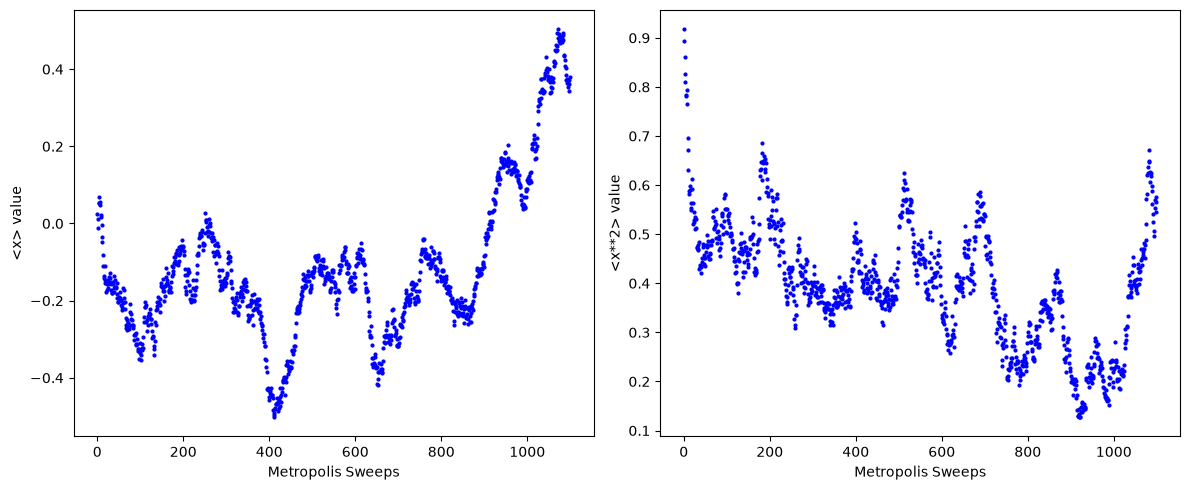

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#Define Parameters
h = 0.5 #step size
m = omega = hbar = 1.0
N_tau = 100 #size of the lattice
path = np.random.randn(N_tau)
beta = 10
delta_tau = beta / N_tau

#length of path is N_tau
def local_action(path, tau, x, delta_tau, m, omega):
    N_tau = len(path)

    # Every site needs two neighbours but the array only has indicies from
    # 0 to N_tau-1, so the two ends would run off the array
    # the %N wraps the values around so the periodic boundary conditions are satisfied
    left = path[(tau - 1) % N_tau]
    right = path[(tau + 1) % N_tau] #double check modulo

    kinetic = (m / (2 * delta_tau) 
               * ((x - left)**2 + (right - x)**2))

    potential = (delta_tau
        * 0.5 * m * (omega**2) * (x**2))
    
    return kinetic + potential

#for every lattice site:
    #choose a site               (1)
    #propose a new x             (2)
    #calculate ΔS                (3)
    #decide whether to accept    (4)

def metropolis_sweep(path, delta_tau):
    N_tau = len(path) #define number of elements in time lattice

    for i in range(N_tau):
        tau = np.random.randint(N_tau) #(1), choosing random site to start at
        j = np.random.uniform(-h,h) #generating the amount to change the site to

        x_old = path[tau] #defining old position in array
        x_new = x_old + j #(2)

        S_old = local_action(path, tau, x_old, delta_tau, m, omega)
        S_new = local_action(path, tau, x_new, delta_tau, m, omega)

        dS = S_new - S_old #(3)
        if dS <= 0 or np.random.rand() < np.exp(-dS): #(4)
            path[tau] = x_new
                # New values that lower the action are always accepted
                # While those that would increase the action are 
                # accepted with probablity exp(-delta_S)

    return path

#value of x and x^2, sweep through lattice one and measure and continue, and then get the average 
# make a plot of raw data against computer time (x^2 will oscillate around some non-zero value)
#aim for acceptance of 60-70%, minimum cost is around there 
#look in literature for the value of x^2 and compare the two
#error bars, next week naive error bars variance divide by root n (n is number of sweeps), goes down with more data
#read up of correlation functions
#autocrrelation effects the errors (theyre not that interesting but affect thigngs
#naive error bars and plots for x and x^2 (for a couple of parameters, check that it works)
#autocorrelation, calculate for some operator (function of x) --> when it redues into noise, stop integrating there
# naive error will be corrected by the autocorrelation factor  (trying to get more reliable error bars) test with operator x^2 
#next couple of weeks, good if you make a note or two 
#unit tests, package unit test in python which helps, helpful in figuring out what ought to be true 

N_therm = 100 #how many of the first sweeps are discarded
N_sweeps = 1000 #how many passes are repeated

x = []
x_2 = []

for i in range(N_therm + N_sweeps):
    total_path = metropolis_sweep(path, delta_tau)
    x.append(np.mean(total_path))
    x_2.append(np.mean(total_path**2))

#slicing to get rid of first N_therm sweeps for thermalisation
x_thermalised = np.array(x[N_therm:])
x_2_thermalised = np.array(x_2[N_therm:])

sweeps = np.arange(len(x))
fig, ax = plt.subplots(1, 2, figsize=(12,5))
ax[0].plot(sweeps, x, 'o', color="blue", markersize=2)
ax[0].set_xlabel("Metropolis Sweeps")
ax[0].set_ylabel("<x> value")

ax[1].plot(sweeps, x_2, 'o', color="blue", markersize=2)
ax[1].set_xlabel("Metropolis Sweeps")
ax[1].set_ylabel("<x**2> value")

plt.tight_layout()
plt.show()